# Excitation & *N*-Temperature-Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/02-heat/01-excitation_NTM.ipynb)

In this example the laser-excitation of a sample {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` is shown.
It includes the actual absorption of the laser light as well as the transient temperature profile calculation.

## Setup

Do all necessary imports and settings.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim[refractiveindex]
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

try:
    plt.style.use(["mbistyles.base", "mbistyles.paper"])  # matplotlib styles of the MBI
except OSError:
    pass  # mbistyles is not installed, the default matplotlib style is used

## Structure

The sample is a thin Fe film on a transparent MgO substrate.
The optical constants of Fe of {cite:t}`johnson1974` are taken from the [refractiveindex.info](https://refractiveindex.info) database {cite}`polyanskiy2024`, see the [dielectric example](#example_dielectric), while MgO is described by a constant refractive index.
The thermal parameters are typical values of both materials.
The layers are given without atoms, as they are not needed for the heat simulations, see the [structure example](#example_structure) for more details.

In [2]:
# Fe with the optical constants of Johnson and Christy
Fe = ud.Layer(
    "Fe",
    "Iron",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=7874 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=449 * u.J / (u.kg * u.K),
        therm_cond=80 * u.W / (u.m * u.K),
    ),
    optical=ud.OpticalParameters(
        dielectric=ud.Dispersion.from_refractiveindex("main", "Fe", "Johnson")
    ),
)

# transparent MgO substrate
MgO = ud.Layer(
    "MgO",
    "Magnesium Oxide",
    structural=ud.StructuralParameters(thickness=1 * u.nm, density=3580 * u.kg / u.m**3),
    thermal=ud.ThermalParameters(
        heat_capacity=923 * u.J / (u.kg * u.K),
        therm_cond=50 * u.W / (u.m * u.K),
    ),
    optical=ud.OpticalParameters(dielectric=ud.Dispersion.from_ref_index(1.73)),
)

In [3]:
S = ud.Structure("Fe on MgO")
S.add_sub_structure(Fe, 20)  # add 20 nm of Fe
S.add_sub_structure(MgO, 100)  # add 100 nm of MgO

:::{versionchanged} 2.5.0

By default the `superstrate` and `substrate` of the {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` are {py:class}`Vacuum <udkm1Dsim.structures.layers.Vacuum>`.
This changes the default behaviour of light and X-ray scattering as shown below.

:::

## Initialize Heat

The {py:class}`Heat <udkm1Dsim.simulations.heat.Heat>` class requires a {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` object and a boolean `force_recalc` in order overwrite previous simulation results.

These results are saved in the `cache_dir` when `save_data` is enabled.
Printing simulation messages can be en-/disabled using `disp_messages` and progress bars can using the boolean switch `progress_bar`.

In [4]:
h = ud.Heat(S, True)

h.save_data = False
h.disp_messages = True

h

parameter,value
force recalc,True
cache directory,./
display messages,True
save data,False
progress bar,True
excitation fluence,[] mJ/cm²
excitation delay,0 ps
excitation pulse length,0 ps
excitation wavelength,800 nm
excitation theta,90 deg


## Simple Excitation

In order to calculate the temperature of the sample after quasi-instantaneous (delta) photoexcitation the `excitation` must be set with the following parameters:
* `fluence`
* `delay_pump`
* `pulse_width`
* `absorption`
* `wavelength`
* `polarization`
* `theta`
* `azimuth`
* `backside`

The angle of incidence `theta` does change the footprint of the excitation on the sample for any type excitation.
The `absorption` profile is calculated by a multilayer formalism, by default {py:class}`Parratt <udkm1Dsim.simulations.scattering.parratt.Parratt>`, which includes the reflection and interference of the light at all interfaces.
Here, the `wavelength` and `theta` angle of the excitation are also relevant, as well as the `polarization`, which is `sigma` or `s`, `pi` or `p`, `unpolarized`, `circ +` or `c+`, or `circ -` or `c-`, as for the multilayer formalisms.
The `azimuth` rotates the plane of incidence relative to the fixed sample, which matters for anisotropic or in-plane magnetized layers only, see the [anisotropic layers example](#example_anisotropic_layers).
Magnetic layers require the formalisms {py:class}`Elzo <udkm1Dsim.simulations.scattering.elzo.Elzo>` or {py:class}`Stepanov <udkm1Dsim.simulations.scattering.stepanov.Stepanov>`, e.g. for the magnetic circular dichroism of the absorption, and anisotropic layers the formalisms {py:class}`BerremanElzo <udkm1Dsim.simulations.scattering.berreman.BerremanElzo>` or {py:class}`BerremanStepanov <udkm1Dsim.simulations.scattering.berreman.BerremanStepanov>`.
The formalisms of Stepanov use the stable scattering-matrix recursion instead of the transfer matrices, e.g. for thick or strongly absorbing structures, see the [scattering overview](#example_scattering_overview).
A configured instance of a formalism can also be given as `absorption`, which then defines the `wavelength`, `theta`, `azimuth`, and `polarization` of the excitation.

For `absorption = "lambert_beer"` the _Lambert-Beer_-law is used and its absorption profile is independent of `theta` and the `polarization`.

With `backside = True` the excitation is calculated to happen from the backside of the sample structure.  
The `fluence`, `delay_pump`, and `pulse_width` are given either as scalars for a single pulse or as arrays or lists with one value per pulse for a multi-pulse excitation as shown below.

The simulation requires also a `delay` array as temporal grid as well as an initial temperature `init_temp`.
The later can be either a scalar which is then the constant temperature of the whole sample structure, or the initial temperature can be an array of temperatures for each single layer in the structure.

:::{important}
The laser excitation is always calculated assuming the static sample -- there is no back action of the excitaion on the laser absorption.
**This is also true for multi-pulse excitations!**
:::

In [5]:
h.excitation = {
    "fluence": 5 * u.mJ / u.cm**2,
    "delay_pump": 0 * u.ps,
    "pulse_width": 0 * u.ps,
    "absorption": ud.Parratt,
    "wavelength": 800 * u.nm,
    "polarization": "pi",
    "theta": 45 * u.deg,
    "backside": False,
}

# the Lambert-Beer law uses the optical penetration depth of the layers,
# which follows from their refractive index for the wavelength of the excitation

# temporal and spatial grid
delays = np.r_[-10:200:0.1] * u.ps
_, _, distances = S.layer_distances

### Laser Absorption Profile

Here the difference in the spatial laser absorption profile is shown between the multilayer formalism and the Lambert-Beer law.  
Note that Lambert-Beer does not include reflection of the incident light from the surface of the sample structure:

Absorption of pulse 0 at 0 ps by Parratt for 800 nm, theta = 45 deg, azimuth = 0 deg, sigma polarization, frontside: reflection of 62.5 %, absorption in the sample of 19.9 %, and transmission into the substrate of 17.6 %.
Absorption of pulse 0 at 0 ps by Parratt for 800 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 34.7 %, absorption in the sample of 38.2 %, and transmission into the substrate of 27.1 %.
Absorption of pulse 0 at 0 ps by Lambert-Beer's law for 800 nm, frontside: absorption in the sample of 65.1 %.


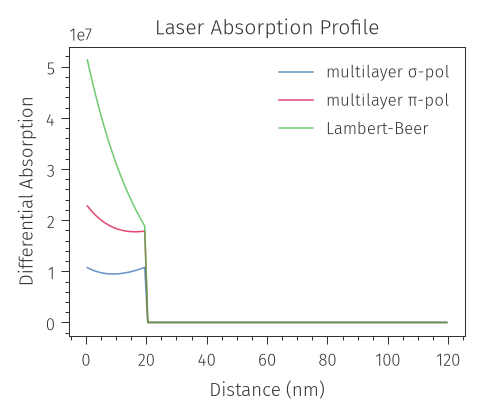

In [6]:
plt.figure()
h.excitation = {"polarization": "sigma"}
dAdz = h.get_absorption_from_multilayer()
plt.plot(distances.to("nm"), dAdz, label="multilayer σ-pol")

h.excitation = {"polarization": "pi"}
dAdz = h.get_absorption_from_multilayer()
plt.plot(distances.to("nm"), dAdz, label="multilayer π-pol")

dAdz = h.get_absorption_from_lambert_beer()
plt.plot(distances.to("nm"), dAdz, label="Lambert-Beer")
plt.legend()
plt.xlabel("Distance (nm)")
plt.ylabel("Differential Absorption")
plt.title("Laser Absorption Profile")
plt.show()

### Configured Multilayer Formalism

Instead of a formalism class, a configured instance of a formalism can be given as `absorption` of the excitation, which must be created for the same {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` as the {py:class}`Heat <udkm1Dsim.simulations.heat.Heat>` simulation.
This allows for all settings of the formalism, which cannot be given in the `excitation` dict.
For example, an `elliptical` polarization is only supported by an instance, as it requires the azimuth angle $\alpha$ and the ellipticity $e$ of the polarization, see {py:meth}`set_incoming_polarization() <udkm1Dsim.simulations.scattering.multilayer.MultilayerScattering.set_incoming_polarization>`.
Here, a {py:class}`Parratt <udkm1Dsim.simulations.scattering.parratt.Parratt>` instance is configured for a pump at 400 nm with an elliptical polarization of $\alpha = 45°$ and $e = 0.5$ and an incidence angle of 60°, see the [scattering overview](#example_scattering_overview) for more details on the configuration of the formalisms.
Its `wavelength`, `theta`, `azimuth`, and `polarization` are then taken for the excitation and must not be given additionally, as shown in the table of the simulation:

Absorption of pulse 0 at 0 ps by Parratt for 800 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 34.7 %, absorption in the sample of 38.2 %, and transmission into the substrate of 27.1 %.
Absorption of pulse 0 at 0 ps by Parratt for 400 nm, theta = 60 deg, azimuth = 0 deg, elliptical polarization, frontside: reflection of 42.1 %, absorption in the sample of 47.2 %, and transmission into the substrate of 10.7 %.


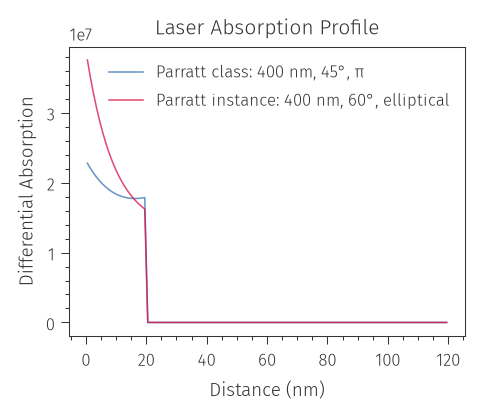

parameter,value
force recalc,True
cache directory,./
display messages,True
save data,False
progress bar,True
excitation fluence,5 mJ/cm²
excitation delay,0 ps
excitation pulse length,0 ps
excitation wavelength,400 nm
excitation theta,60 deg


In [7]:
parratt = ud.Parratt(S, True)
parratt.save_data = False
parratt.disp_messages = False
parratt.wl = np.r_[400] * u.nm
parratt.theta = np.r_[60] * u.deg
# azimuth angle alpha and ellipticity e of the polarization
parratt.set_incoming_polarization("elliptical", (45 * u.deg, 0.5))

plt.figure()
dAdz = h.get_absorption_from_multilayer()
plt.plot(distances.to("nm"), dAdz, label="Parratt class: 400 nm, 45°, π")

h.excitation = {"absorption": parratt}
dAdz = h.get_absorption_from_multilayer()
plt.plot(distances.to("nm"), dAdz, label="Parratt instance: 400 nm, 60°, elliptical")
plt.legend()
plt.xlabel("Distance (nm)")
plt.ylabel("Differential Absorption")
plt.title("Laser Absorption Profile")
plt.show()

h

For the following sections, the formalism class is set again together with the former `wavelength`, `theta`, and `polarization` of the excitation:

In [8]:
h.excitation = {
    "absorption": ud.Parratt,
    "wavelength": 400 * u.nm,
    "polarization": "pi",
    "theta": 45 * u.deg,
}

### Backside Excitation

The same calculation is repeated with the pump laser entering from the backside of the sample of the structure within the multilayer formalism.  
The clear difference in absorbed energy stems from the significantly different reflectivity of the pump light for front- or backside excitation due to better or worse refractive-index matching.

:::{attention}

For direct comparison, the semi-infinite `superstrate` and `substrate` of your sample must be the same -- typically {py:class}`Vacuum <udkm1Dsim.structures.layers.Vacuum>`!

:::

Absorption of pulse 0 at 0 ps by Parratt for 400 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 31.8 %, absorption in the sample of 52.8 %, and transmission into the substrate of 15.4 %.
Absorption of pulse 0 at 0 ps by Parratt for 400 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, backside: reflection of 30.8 %, absorption in the sample of 53.8 %, and transmission into the substrate of 15.4 %.


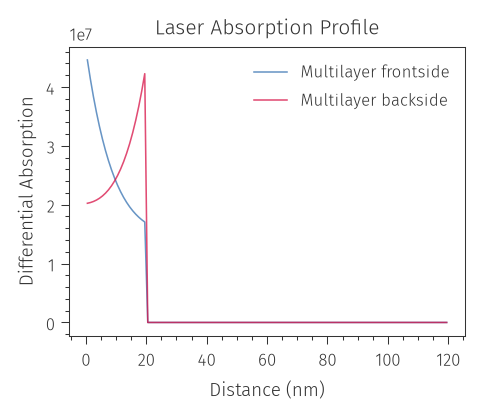

In [9]:
plt.figure()
h.excitation = {"backside": False}
dAdz = h.get_absorption_from_multilayer()
plt.plot(distances.to("nm"), dAdz, label="Multilayer frontside")
h.excitation = {"backside": True}
dAdz = h.get_absorption_from_multilayer()
plt.plot(distances.to("nm"), dAdz, label="Multilayer backside")
h.excitation = {"backside": False}
plt.legend()
plt.xlabel("Distance (nm)")
plt.ylabel("Differential Absorption")
plt.title("Laser Absorption Profile")
plt.show()

### Semi-infinite Substrate

:::{versionchanged} 2.5.0

Before this version, the last {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` of the {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` was assumed to be **semi-infinite** within the multilayer light-scattering formalism.
This assumption worked well for many samples on substrates but lead to issues
for thin or optically highly transparent samples.

This silent behavior is now removed and a semi-infinite {py:class}`Layer <udkm1Dsim.structures.layers.Layer>` (other than
{py:class}`Vacuum <udkm1Dsim.structures.layers.Vacuum>`) must be added manually by the user.

:::

Absorption of pulse 0 at 0 ps by Parratt for 400 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 31.8 %, absorption in the sample of 52.8 %, and transmission into the substrate of 15.4 %.
Absorption of pulse 0 at 0 ps by Parratt for 400 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 33.3 %, absorption in the sample of 49.2 %, and transmission into the substrate of 17.5 %.


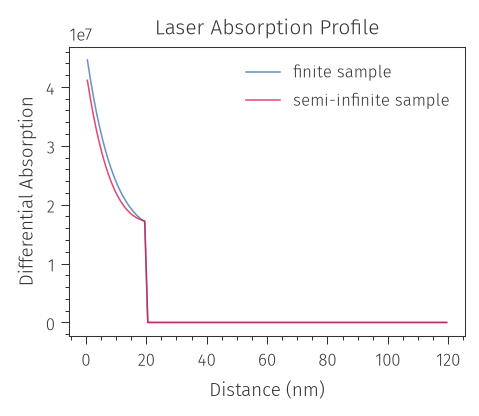

In [10]:
plt.figure()
dAdz = h.get_absorption_from_multilayer()
plt.plot(distances.to("nm"), dAdz, label="finite sample")

# add semi-infinite layer as substrate
S.add_substrate(MgO)
dAdz = h.get_absorption_from_multilayer()
plt.plot(distances.to("nm"), dAdz, label="semi-infinite sample")

plt.legend()
plt.xlabel("Distance (nm)")
plt.ylabel("Differential Absorption")
plt.title("Laser Absorption Profile")
plt.show()

### Reflectivity and Fields of the Excitation

The multilayer formalism of the excitation is created by {py:meth}`create_multilayer_formalism() <udkm1Dsim.simulations.heat.Heat.create_multilayer_formalism>`.
It provides the reflectivity of the pump light as well as the electric field inside the structure, whose intensity is shown for the incident $s$- and $p$-polarization, see the [optical example](#example_anisotropic_layers) for more details:

reflectivity: 0.333


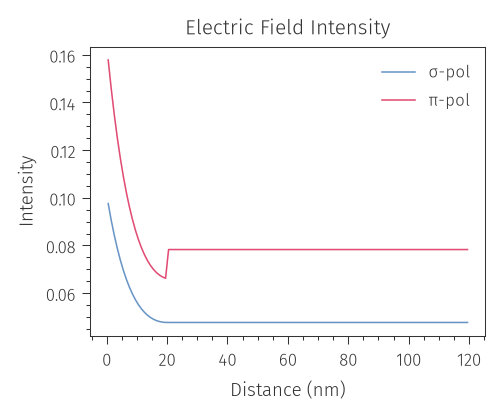

In [11]:
formalism = h.create_multilayer_formalism()
print(f"reflectivity: {formalism.homogeneous_reflectivity_transmissivity().R.item():.3f}")

fields = formalism.homogeneous_fields(distances)
# intensity of the electric field for the incident s- and p-polarization
intensity = np.sum(np.abs(fields.E[0, 0]) ** 2, axis=1)

plt.figure()
plt.plot(distances.to("nm"), intensity[:, 0], label="σ-pol")
plt.plot(distances.to("nm"), intensity[:, 1], label="π-pol")
plt.legend()
plt.xlabel("Distance (nm)")
plt.ylabel("Intensity")
plt.title("Electric Field Intensity")
plt.show()

### Bandwidth and Divergence of the Excitation

:::{versionadded} 3.0.0
:::

Real pump pulses have a finite spectral `bandwidth`, and focused beams have an angular spread, the `divergence` in the plane of incidence, which are given as FWHM in the excitation.
They change the absorption profile for two reasons:

* The interference of the light in thin films and multilayers depends on the wavelength and the angle, so that interference fringes, e.g. of transparent layers, are averaged out.
* The refractive index depends on the wavelength, which changes the penetration depth and the reflectivity, and indirectly also the interference, e.g. close to absorption edges.

The absorption profile of a pulse is the weighted mean of the profiles at the wavelengths and angles of the nodes of {py:func}`profile_nodes() <udkm1Dsim.simulations.scattering.instrument.profile_nodes>`, which are sampled as for the [instrument function](#example_instrument_function), see {py:meth}`get_absorption_profile() <udkm1Dsim.simulations.heat.Heat.get_absorption_profile>`.
A `bandwidth` in a length unit is a profile in the wavelength, while a `bandwidth` in an energy unit, e.g. `0.1 * u.eV`, is a profile in the photon energy.
The fluence is projected onto the surface by the central angle `theta`, as all rays of a pulse hit the same spot.

Here, the interference is shown, as the optical constants of Fe change only weakly around 800 nm.
In order to show this, a 10 nm thin Fe film on about 2.4 µm of MgO is excited by a pulse of 50 nm bandwidth, which is sampled by 21 nodes:

In [12]:
S_film = ud.Structure("Fe film on thick MgO")
S_film.add_sub_structure(Fe, 10)  # add 10 nm of Fe
S_film.add_sub_structure(MgO, 2400)  # add 2.4 µm of MgO
# depths of the Fe film, where the absorption profiles are calculated
select = S_film.positions_per_unique_layer["Fe"]
distances_film = S_film.layer_distances[2][select]

h_film = ud.Heat(S_film, True)
h_film.save_data = False
h_film.disp_messages = True
h_film.excitation = {
    "fluence": 5 * u.mJ / u.cm**2,
    "delay_pump": 0 * u.ps,
    "pulse_width": 0 * u.ps,
    "wavelength": 800 * u.nm,
    "theta": 45 * u.deg,
    "polarization": "pi",
    "bandwidth": 50 * u.nm,
    "bandwidth_points": 21,
}

h_film

parameter,value
force recalc,True
cache directory,./
display messages,True
save data,False
progress bar,True
excitation fluence,5 mJ/cm²
excitation delay,0 ps
excitation pulse length,0 ps
excitation wavelength,800 nm
excitation theta,45 deg


As the MgO is transparent, the absorption of the Fe film is $1 - R - T$, which is calculated by the formalism of the excitation for a dense scan of the wavelength.
The back side of the MgO causes Fabry-Pérot fringes with a period of about $\lambda^2 / (2 n d \cos\vartheta_t) \approx 85$ nm, where $\vartheta_t$ is the angle inside the MgO.
The nodes and their weights are returned by {py:meth}`get_pulse_nodes() <udkm1Dsim.simulations.heat.Heat.get_pulse_nodes>`, which are shown by the size of the markers, and the formalism at the nodes is created by `create_multilayer_formalism(nodes=True)`.
The absorption of the pulse is the weighted mean over the nodes, which approaches the mean over the fringes for bandwidths larger than their period.
As the monochromatic pulse at 800 nm is close to a minimum of the fringes, the pulse with a bandwidth of 50 nm is absorbed more by about 6 percentage points, i.e. 35.6 % instead of 29.5 %, but still less than the mean of about 37 % over the fringes, as its bandwidth is shorter than their period:

Absorption of pulse 0 at 0 ps by Parratt for 800 nm (FWHM 50 nm, gauss, 21 uniform nodes), theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 19.7 %, absorption in the sample of 35.6 %, and transmission into the substrate of 44.7 %.


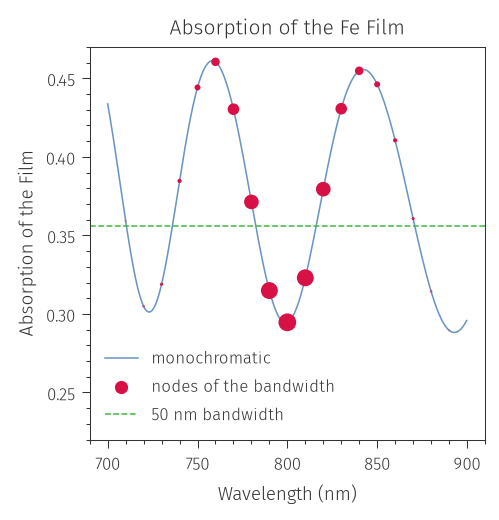

In [13]:
# monochromatic absorption of the film for a dense scan of the wavelength
formalism = h_film.create_multilayer_formalism()
formalism.wl = np.r_[700:900:0.25] * u.nm
res_rt = formalism.homogeneous_reflectivity_transmissivity()

# absorption of the film at the nodes of the bandwidth
nodes = h_film.create_multilayer_formalism(nodes=True)
res_nodes = nodes.homogeneous_reflectivity_transmissivity()
wavelengths, _, weights = h_film.get_pulse_nodes()

# absorbed fraction of the film from the mean absorption profile
dAdz = h_film.get_absorption_profile(distances_film.to("m").magnitude)
absorbed = np.sum(dAdz) * Fe.thickness.to("m").magnitude

plt.figure(figsize=[3.4, 3.4])
plt.plot(formalism.wl, 1 - res_rt.R[:, 0] - res_rt.T[:, 0], label="monochromatic")
plt.scatter(
    wavelengths,
    1 - res_nodes.R[:, 0] - res_nodes.T[:, 0],
    s=300 * weights[:, 0],
    color="C1",
    label="nodes of the bandwidth",
    zorder=3,
)
plt.axhline(absorbed, color="C2", ls="--", label="50 nm bandwidth")
plt.ylim(0.22, 0.47)
plt.xlabel("Wavelength (nm)")
plt.ylabel("Absorption of the Film")
plt.legend()
plt.title("Absorption of the Fe Film")
plt.show()

The nodes must resolve the fringes, which is checked best by increasing the number of `bandwidth_points`, as shown by the reported absorption in the sample, which is the absorption of the Fe film and converges for 11 and more nodes.
Three uniform nodes give the monochromatic value, as the weights of their outer nodes at the `bandwidth_range` of ±2 FWHM vanish.
As for the [instrument function](#example_instrument_function), uniform nodes, which are too coarse for the profile itself, are warned for, here 3 and 5 nodes:

In [14]:
for points in [3, 5, 7, 11, 21, 41]:
    h_film.excitation = {"bandwidth_points": points}
    dAdz = h_film.get_absorption_profile(distances_film.to("m").magnitude)

Absorption of pulse 0 at 0 ps by Parratt for 800 nm (FWHM 50 nm, gauss, 3 uniform nodes), theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 23.7 %, absorption in the sample of 29.5 %, and transmission into the substrate of 46.8 %.
Absorption of pulse 0 at 0 ps by Parratt for 800 nm (FWHM 50 nm, gauss, 5 uniform nodes), theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 22.6 %, absorption in the sample of 31.1 %, and transmission into the substrate of 46.3 %.


/tmp/ipykernel_884273/3820231634.py:2: UserWarning: The 3 uniform nodes of the bandwidth of the pulse 0 are 2 FWHM apart within the bandwidth_range of 2 FWHM, which is too coarse for the profile, so that the bandwidth of the pulse 0 is wrong, e.g. too small or too large! Use at least 7 bandwidth_points for this range.
  h_film.excitation = {"bandwidth_points": points}
/tmp/ipykernel_884273/3820231634.py:2: UserWarning: The 5 uniform nodes of the bandwidth of the pulse 0 are 1 FWHM apart within the bandwidth_range of 2 FWHM, which is too coarse for the profile, so that the bandwidth of the pulse 0 is wrong, e.g. too small or too large! Use at least 7 bandwidth_points for this range.
  h_film.excitation = {"bandwidth_points": points}


Absorption of pulse 0 at 0 ps by Parratt for 800 nm (FWHM 50 nm, gauss, 7 uniform nodes), theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 20.1 %, absorption in the sample of 35.0 %, and transmission into the substrate of 44.9 %.
Absorption of pulse 0 at 0 ps by Parratt for 800 nm (FWHM 50 nm, gauss, 11 uniform nodes), theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 19.7 %, absorption in the sample of 35.6 %, and transmission into the substrate of 44.7 %.
Absorption of pulse 0 at 0 ps by Parratt for 800 nm (FWHM 50 nm, gauss, 21 uniform nodes), theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 19.7 %, absorption in the sample of 35.6 %, and transmission into the substrate of 44.7 %.
Absorption of pulse 0 at 0 ps by Parratt for 800 nm (FWHM 50 nm, gauss, 41 uniform nodes), theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 19.7 %, absorption in the sample of 35.6 %, and transmission int

The `divergence` acts in the same way on the angle of incidence, as the fringes also shift with the angle, so that it adds to the averaging by the bandwidth.
Here, the absorption profiles of the film are compared for a monochromatic and collimated pulse, the bandwidth of 50 nm, and an additional divergence of 10°, which increases the absorption of the film further from 35.6 % to 36.3 %:

Absorption of pulse 0 at 0 ps by Parratt for 800 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 23.7 %, absorption in the sample of 29.5 %, and transmission into the substrate of 46.8 %.
Absorption of pulse 0 at 0 ps by Parratt for 800 nm (FWHM 50 nm, gauss, 21 uniform nodes), theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 19.7 %, absorption in the sample of 35.6 %, and transmission into the substrate of 44.7 %.
Absorption of pulse 0 at 0 ps by Parratt for 800 nm (FWHM 50 nm, gauss, 21 uniform nodes), theta = 45 deg (FWHM 10 deg, gauss, 7 uniform nodes), azimuth = 0 deg, pi polarization, frontside: reflection of 19.2 %, absorption in the sample of 36.3 %, and transmission into the substrate of 44.5 %.


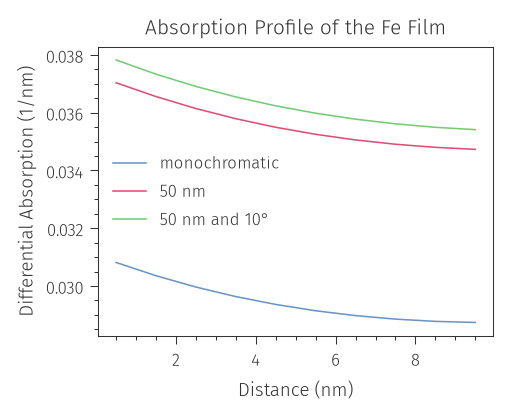

In [15]:
h_film.excitation = {"bandwidth_points": 21}

plt.figure()
for label, spreads in [
    ("monochromatic", {"bandwidth": 0 * u.nm}),
    ("50 nm", {"bandwidth": 50 * u.nm}),
    ("50 nm and 10°", {"divergence": 10 * u.deg}),
]:
    h_film.excitation = spreads
    dAdz = h_film.get_absorption_profile(distances_film.to("m").magnitude) / u.m
    plt.plot(distances_film.to("nm"), dAdz.to("1/nm"), label=label)
plt.xlabel("Distance (nm)")
plt.ylabel("Differential Absorption (1/nm)")
plt.legend()
plt.title("Absorption Profile of the Fe Film")
plt.show()

Finally, the pump at 800 nm is compared for a monochromatic pulse and a broadband pulse of 100 nm bandwidth, e.g. of a few-cycle laser, which spans more than one period of the fringes and is sampled by 81 nodes of 5 nm spacing within ±2 FWHM.
Here, the temperature rise of the film right after the excitation by a surface fluence of 5 mJ/cm² is calculated by {py:meth}`get_temperature_after_delta_excitation() <udkm1Dsim.simulations.heat.Heat.get_temperature_after_delta_excitation>`.
The broadband pulse is absorbed by 37.9 %, i.e. the mean over the fringes, so that it heats the film by about 120 K more than the monochromatic pulse:

Absorption of pulse 0 at 0 ps by Parratt for 800 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 23.7 %, absorption in the sample of 29.5 %, and transmission into the substrate of 46.8 %.
Absorption of pulse 0 at 0 ps by Parratt for 800 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 23.7 %, absorption in the sample of 29.5 %, and transmission into the substrate of 46.8 %.
Elapsed time for _temperature_after_delta_excitation_: 0.163550 s
Absorption of pulse 0 at 0 ps by Parratt for 800 nm (FWHM 100 nm, gauss, 81 uniform nodes), theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 18.3 %, absorption in the sample of 37.9 %, and transmission into the substrate of 43.8 %.
Absorption of pulse 0 at 0 ps by Parratt for 800 nm (FWHM 100 nm, gauss, 81 uniform nodes), theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 18.3 %, absorption in the sample of 37.9 %, and transmission into the s

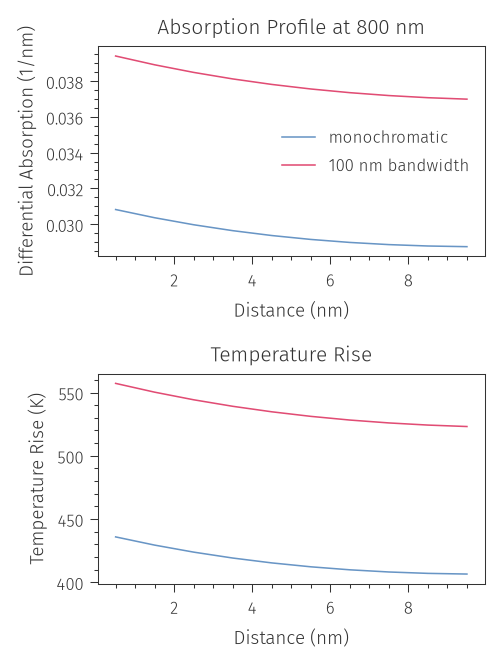

In [16]:
h_film.excitation = {"divergence": 0 * u.deg}

plt.figure(figsize=[3.4, 4.5])
for label, spreads in [
    ("monochromatic", {"bandwidth": 0 * u.nm}),
    ("100 nm bandwidth", {"bandwidth": 100 * u.nm, "bandwidth_points": 81}),
]:
    h_film.excitation = spreads
    dAdz = h_film.get_absorption_profile(distances_film.to("m").magnitude) / u.m
    res_delta = h_film.get_temperature_after_delta_excitation(
        5 * u.mJ / u.cm**2, 300 * u.K, distances_film.to("m").magnitude
    )

    plt.subplot(2, 1, 1)
    plt.plot(distances_film.to("nm"), dAdz.to("1/nm"), label=label)
    plt.subplot(2, 1, 2)
    plt.plot(distances_film.to("nm"), res_delta.quantity("delta_temp", "K")[:, 0], label=label)

plt.subplot(2, 1, 1)
plt.xlabel("Distance (nm)")
plt.ylabel("Differential Absorption (1/nm)")
plt.legend()
plt.title("Absorption Profile at 800 nm")
plt.subplot(2, 1, 2)
plt.xlabel("Distance (nm)")
plt.ylabel("Temperature Rise (K)")
plt.title("Temperature Rise")
plt.tight_layout()
plt.show()

### Temperature Map

Calculating a tranient temperature map is only a one-line command.
It returns a {py:class}`Result <udkm1Dsim.simulations.result.Result>` `res_temp` with the `temp_map` and `delta_temp_map` and their coordinates `delays` and `distances`, which are used for the plots, see the [simulations and results example](#example_simulations_and_results):

In [17]:
res_temp = h.get_temp_map(delays, 300 * u.K)

Surface incidence fluence scaled by factor 0.7071 due to incidence angle theta=45.00 deg
Absorption of pulse 0 at 0 ps by Parratt for 400 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 33.3 %, absorption in the sample of 49.2 %, and transmission into the substrate of 17.5 %.
Elapsed time for _temperature_after_delta_excitation_: 0.001345 s
Elapsed time for _temp_map_: 0.012463 s


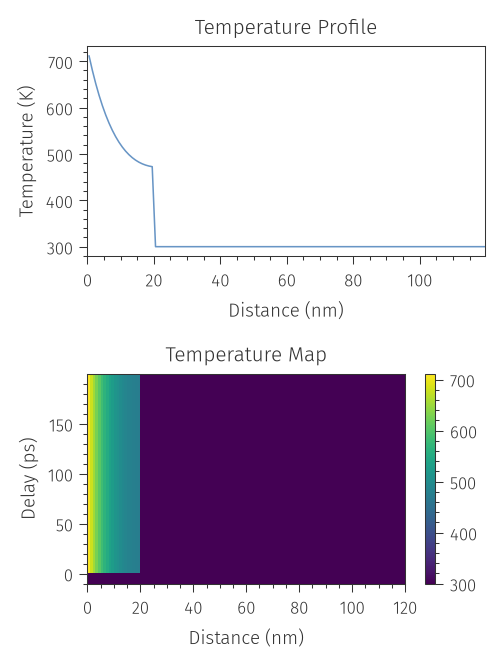

In [18]:
plt.figure(figsize=[3.4, 4.5])
plt.subplot(2, 1, 1)
plt.plot(res_temp.quantity("distances", "nm"), res_temp.temp_map[101, :])
plt.xlim([0, res_temp.quantity("distances", "nm")[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Temperature (K)")
plt.title("Temperature Profile")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_temp.quantity("distances", "nm"),
    res_temp.quantity("delays", "ps"),
    res_temp.temp_map,
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map")

plt.tight_layout()
plt.show()

## Heat Diffusion

In order to enable heat diffusion the boolean switch `heat_diffusion` must be `True`.  
It is also reasonable to define a finte pump `pulse_width`.

In [19]:
# enable heat diffusion
h.heat_diffusion = True
# set the boundary conditions
h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}
# change only the pulse duration
h.excitation = {"pulse_width": [0.1] * u.ps}
# the resulting temperature profile is calculated in one line
res_temp = h.get_temp_map(delays, 300 * u.K)

Surface incidence fluence scaled by factor 0.7071 due to incidence angle theta=45.00 deg
Absorption of pulse 0 at 0 ps by Parratt for 400 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 33.3 %, absorption in the sample of 49.2 %, and transmission into the substrate of 17.5 %.
Calculating _heat_diffusion_ for pulse 0 of 1 ...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_ with 1 excitation(s): 0.072345 s
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.029598 s
Elapsed time for _temp_map_: 0.127378 s


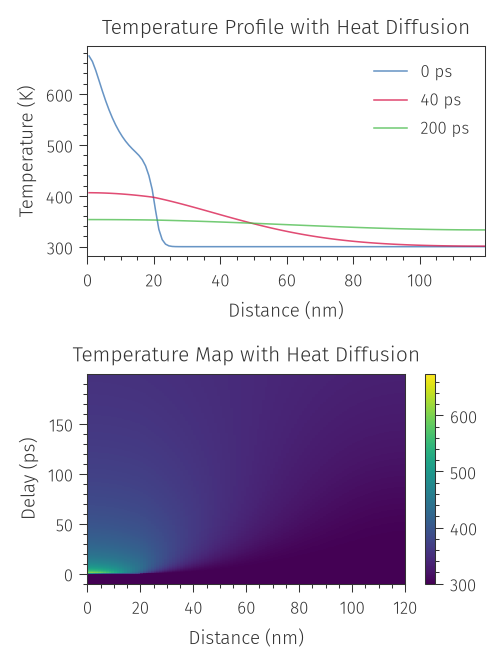

In [20]:
plt.figure(figsize=[3.4, 4.5])
plt.subplot(2, 1, 1)
plt.plot(
    res_temp.quantity("distances", "nm"),
    res_temp.temp_map[101, :],
    label=np.round(res_temp.quantity("delays", "ps")[101]),
)
plt.plot(
    res_temp.quantity("distances", "nm"),
    res_temp.temp_map[501, :],
    label=np.round(res_temp.quantity("delays", "ps")[501]),
)
plt.plot(
    res_temp.quantity("distances", "nm"),
    res_temp.temp_map[-1, :],
    label=np.round(res_temp.quantity("delays", "ps")[-1]),
)
plt.xlim([0, res_temp.quantity("distances", "nm")[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Temperature Profile with Heat Diffusion")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_temp.quantity("distances", "nm"),
    res_temp.quantity("delays", "ps"),
    res_temp.temp_map,
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map with Heat Diffusion")

plt.tight_layout()
plt.show()

### Heat Diffusion Parameters

For heat diffusion simulations various parameters for the underlying pdepe solver can be altered.
The `ode_options` can be configured and are directly handed to the actual solver.
Please refer to the documentation of the solver and the __API documentation__ for more details.

The speed but also the result of the heat diffusion simulation strongly depends on the spatial grid handed to the solver.
By default, one spatial grid point is used for every {py:class}`Layer <udkm1Dsim.structures.layers.Layer>`, e.g. also a {py:class}`UnitCell <udkm1Dsim.structures.layers.UnitCell>`, in the {py:class}`Structure <udkm1Dsim.structures.structure.Structure>`.
The resulting `temp_map` will also always be interpolated in this spatial grid which is equivalent to the distance vector returned by `S.layer_distances`.

As the solver for the heat diffusion usually suffers from large gradients, e.g. of thermal properties or initial temperatures, additional spatial grid points are added by default only for internal calculations.
The number of additional points (should be an odd number, default is 11) is set by:

In [21]:
h.intp_at_interface = 11

The internally used spatial grid can be returned by:

In [22]:
dist_interp, original_indicies = S.interp_distance_at_interfaces(h.intp_at_interface)

The internal spatial grid can also be given by hand, e.g. to realize logarithmic steps for rather large {py:class}`Structure <udkm1Dsim.structures.structure.Structure>`s:

In [23]:
h.distances = np.linspace(0, distances.magnitude[-1], 100) * u.m

As already shown above, the heat diffusion simulation also supports a top and bottom boundary condition.
They can have the types:
* `isolator`
* `temperature`
* `flux`

For the latter types, a value must also be provided:

In [24]:
h.boundary_conditions = {
    "top_type": "temperature",
    "top_value": 500 * u.K,
    "bottom_type": "flux",
    "bottom_value": 5e11 * u.W / u.m**2,
}

h

parameter,value
force recalc,True
cache directory,./
display messages,True
save data,False
progress bar,True
excitation fluence,5 mJ/cm²
excitation delay,0 ps
excitation pulse length,0.1 ps
excitation wavelength,400 nm
excitation theta,45 deg


In [25]:
# the resulting temperature profile is calculated in one line
res_temp = h.get_temp_map(delays, 300 * u.K)

Surface incidence fluence scaled by factor 0.7071 due to incidence angle theta=45.00 deg
Absorption of pulse 0 at 0 ps by Parratt for 400 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 33.3 %, absorption in the sample of 49.2 %, and transmission into the substrate of 17.5 %.
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.032181 s
Calculating _heat_diffusion_ for pulse 0 of 1 ...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_ with 1 excitation(s): 0.074005 s
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.026002 s
Elapsed time for _temp_map_: 0.151788 s


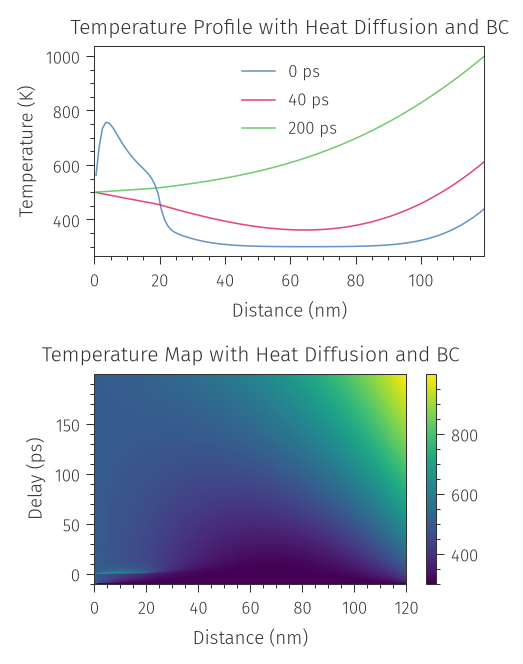

In [26]:
plt.figure(figsize=[3.4, 4.5])
plt.subplot(2, 1, 1)
plt.plot(
    res_temp.quantity("distances", "nm"),
    res_temp.temp_map[101, :],
    label=np.round(res_temp.quantity("delays", "ps")[101]),
)
plt.plot(
    res_temp.quantity("distances", "nm"),
    res_temp.temp_map[501, :],
    label=np.round(res_temp.quantity("delays", "ps")[501]),
)
plt.plot(
    res_temp.quantity("distances", "nm"),
    res_temp.temp_map[-1, :],
    label=np.round(res_temp.quantity("delays", "ps")[-1]),
)
plt.xlim([0, res_temp.quantity("distances", "nm")[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Temperature Profile with Heat Diffusion and BC")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_temp.quantity("distances", "nm"),
    res_temp.quantity("delays", "ps"),
    res_temp.temp_map,
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map with Heat Diffusion and BC")

plt.tight_layout()
plt.show()

## Multipulse Excitation

As already stated above, also multiple pulses of variable fluence, pulse width and, delay are possible.

The heat diffusion simulation automatically splits the calculation in parts with and without excitation and adjusts the initial temporal step width according to the pulse width.
Hence the solver does not miss any excitation pulses when adjusting its temporal step size.

The temporal laser pulse profile is always assumed to be Gaussian and the pulse width must be given as FWHM:

In [27]:
h.excitation = {
    "fluence": [5, 5, 5, 5] * u.mJ / u.cm**2,
    "delay_pump": [0, 10, 20, 20.5] * u.ps,
    "pulse_width": [0.1, 0.1, 0.1, 0.5] * u.ps,
    "wavelength": 800 * u.nm,
    "theta": 45 * u.deg,
    "backside": False,
}

h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}

In [28]:
# the resulting temperature profile is calculated in one line
res_temp = h.get_temp_map(delays, 300 * u.K)

Surface incidence fluence scaled by factor 0.7071 due to incidence angle theta=45.00 deg
Absorption of pulses 0, 1, 2, 3 at 0, 10, 20, 20.5 ps by Parratt for 800 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 31.2 %, absorption in the sample of 44.3 %, and transmission into the substrate of 24.5 %.
Calculating _heat_diffusion_ for pulse 0 of 4 ...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_ with 1 excitation(s): 0.082658 s
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.027420 s
Calculating _heat_diffusion_ for pulse 1 of 4 ...


0it [00:00, ?it/s]

... (3 outputs left out)

0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_ with 2 excitation(s): 0.149516 s
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.024055 s
Elapsed time for _temp_map_: 0.429377 s


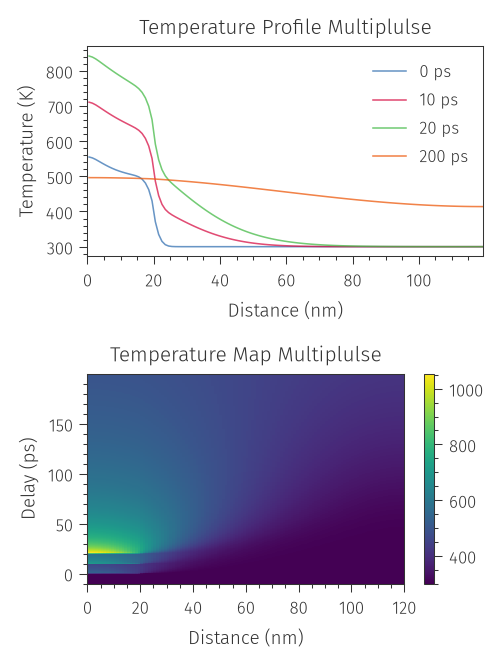

In [29]:
plt.figure(figsize=[3.4, 4.5])
plt.subplot(2, 1, 1)
plt.plot(
    res_temp.quantity("distances", "nm"),
    res_temp.temp_map[101, :],
    label=np.round(res_temp.quantity("delays", "ps")[101]),
)
plt.plot(
    res_temp.quantity("distances", "nm"),
    res_temp.temp_map[201, :],
    label=np.round(res_temp.quantity("delays", "ps")[201]),
)
plt.plot(
    res_temp.quantity("distances", "nm"),
    res_temp.temp_map[301, :],
    label=np.round(res_temp.quantity("delays", "ps")[301]),
)
plt.plot(
    res_temp.quantity("distances", "nm"),
    res_temp.temp_map[-1, :],
    label=np.round(res_temp.quantity("delays", "ps")[-1]),
)
plt.xlim([0, res_temp.quantity("distances", "nm")[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Temperature (K)")
plt.legend()
plt.title("Temperature Profile Multiplulse")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_temp.quantity("distances", "nm"),
    res_temp.quantity("delays", "ps"),
    res_temp.temp_map,
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map Multiplulse")

plt.tight_layout()
plt.show()

### Pulses with Different Parameters

The `wavelength`, `theta`, `azimuth`, `polarization`, `absorption`, and `backside` of the excitation can also be given as lists with one value per pulse, which are sorted by the `delay_pump` together with the pulses.
Here, a pump at 800 nm on the frontside is followed by a pump at 400 nm on the backside after 20 ps, which passes the transparent MgO and is absorbed at the bottom of the Fe film.
The absorption profile of every pulse is part of the result as `absorption`, which is also returned by {py:meth}`get_absorption_profile() <udkm1Dsim.simulations.heat.Heat.get_absorption_profile>`, where the `pulse_index` selects a single pulse in the order of their delays:

Surface incidence fluences scaled by factors [0.7071 0.866 ] due to incidence angles theta=[45. 60.] deg
Absorption of pulse 0 at 0 ps by Parratt for 800 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 31.2 %, absorption in the sample of 44.3 %, and transmission into the substrate of 24.5 %.
Absorption of pulse 1 at 20 ps by Parratt for 400 nm, theta = 60 deg, azimuth = 0 deg, pi polarization, backside: reflection of 22.4 %, absorption in the sample of 57.3 %, and transmission into the substrate of 20.3 %.
Calculating _heat_diffusion_ for pulse 0 of 2 ...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_ with 1 excitation(s): 0.103931 s
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.024335 s
Calculating _heat_diffusion_ for pulse 1 of 2 ...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_ with 1 excitation(s): 0.065294 s
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.023253 s
Elapsed time for _temp_map_: 0.245029 s


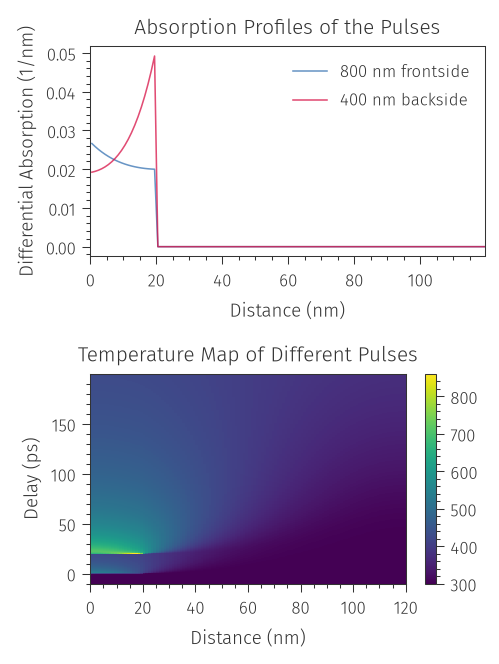

In [30]:
h.excitation = {
    "fluence": [5, 5] * u.mJ / u.cm**2,
    "delay_pump": [0, 20] * u.ps,
    "pulse_width": [0.1, 0.1] * u.ps,
    "wavelength": [800, 400] * u.nm,
    "theta": [45, 60] * u.deg,
    "backside": [False, True],
}

res_temp = h.get_temp_map(delays, 300 * u.K)

plt.figure(figsize=[3.4, 4.5])
plt.subplot(2, 1, 1)
for index, label in enumerate(["800 nm frontside", "400 nm backside"]):
    plt.plot(
        res_temp.quantity("distances", "nm"),
        res_temp.quantity("absorption", "1/nm")[index],
        label=label,
    )
plt.xlim([0, res_temp.quantity("distances", "nm")[-1]])
plt.xlabel("Distance (nm)")
plt.ylabel("Differential Absorption (1/nm)")
plt.legend()
plt.title("Absorption Profiles of the Pulses")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_temp.quantity("distances", "nm"),
    res_temp.quantity("delays", "ps"),
    res_temp.temp_map,
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map of Different Pulses")

plt.tight_layout()
plt.show()

## $N$-Temperature Model

The heat diffusion is also capable of simulating an _N_-temperature model which is often applied to empirically simulate the energy flow between _electrons_, _phonons_, and _spins_.
In order to run the _NTM_ all thermo-elastic properties must be given as a list of _N_ elements corresponding to different sub-systems.
The actual external laser-excitation is always set to happen within the __first__ sub-system, which is usually the electron-system.

In addition the `sub_system_coupling` must be provided in order to allow for energy-flow between the sub-systems.
The sub-systems can be labeled by the `sub_system_labels` of the thermal parameters, which are used for their display only.
`sub_system_coupling` is often set to a constant prefactor multiplied with the difference between the electronic and phononic temperatures, as in the example below.
For sufficiently high temperatures, this prefactor also depends on the temperature.
See [here](https://faculty.virginia.edu/CompMat/electron-phonon-coupling/) for an overview.

In case the thermo-elastic parameters are provided as functions of the temperature $T$, the `sub_system_coupling` requires the temperature `T` to be a vector of all sub-system-temperatures which can be accessed in the function string via the underscore-notation.
The `heat_capacity` and `lin_therm_exp` instead require the temperature `T` to be a scalar of only the current sub-system-temperature.
For the `therm_cond`, both options are available.

In [31]:
# update the relevant thermal properties of the layers in the sample structure
# with a two-temperature model of the electrons and phonons
Fe.heat_capacity = ["0.085*T", 449 * u.J / (u.kg * u.K)]
Fe.therm_cond = [70 * u.W / (u.m * u.K), 10 * u.W / (u.m * u.K)]
Fe.sub_system_coupling = ["-8e17*(T_0-T_1)", "8e17*(T_0-T_1)"]
Fe.thermal.sub_system_labels = ["e", "p"]  # electrons and phonons

MgO.heat_capacity = ["0.01*T", 923 * u.J / (u.kg * u.K)]
MgO.therm_cond = [0, 50 * u.W / (u.m * u.K)]
MgO.sub_system_coupling = ["-1e18*(T_0-T_1)", "1e18*(T_0-T_1)"]
MgO.thermal.sub_system_labels = ["e", "p"]

Fe.thermal

Thermal Parameters
╔═════════════════════╦══════════╦════════════════════════╦════════╗
║ Parameter           ║  Symbol  ║                  Value ║ Unit   ║
╠═════════════════════╬══════════╬════════════════════════╬════════╣
║ therm_cond          ║    κₑ    ║                     70 ║ W/K/m  ║
║                     ║    κₚ    ║                     10 ║        ║
╠═════════════════════╬══════════╬════════════════════════╬════════╣
║ heat_capacity       ║    cₑ    ║               0.085·Tₑ ║ J/K/kg ║
║                     ║    cₚ    ║                    449 ║        ║
╠═════════════════════╬══════════╬════════════════════════╬════════╣
║ lin_therm_exp       ║    αₑ    ║                      0 ║ 1/K    ║
╠═════════════════════╬══════════╬════════════════════════╬════════╣
║ sub_system_coupling ║    Gₑ    ║ −8×10¹⁷·Tₑ + 8×10¹⁷·Tₚ ║ W/m³   ║
║                     ║    Gₚ    ║  8×10¹⁷·Tₑ − 8×10¹⁷·Tₚ ║        ║
╠═════════════════════╬══════════╬════════════════════════╬════════╣
║ deb_wal_fac         ║  ⟨u²⟩ₑ   ║                      0 ║ m²     ║
╠═════════════════════╬══════════╬════════════════════════╬════════╣
║ num_sub_systems     ║    N     ║                      2 ║        ║
╚═════════════════════╩══════════╩════════════════════════╩════════╝

The {py:class}`Structure <udkm1Dsim.structures.structure.Structure>` takes the number of sub-systems `num_sub_systems` automatically from its layers, also when they are changed after being added to the structure.
The consistency of all thermal parameters relevant for a simulation is checked when it is started, so the parameters can be set one after another without any warnings.

In [32]:
S.num_sub_systems

2

Set the excitation conditions:

In [33]:
h.excitation = {
    "fluence": [5] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0.25] * u.ps,
    "wavelength": 800 * u.nm,
    "theta": 45 * u.deg,
    "backside": False,
}

h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}

delays = np.r_[-5:15:0.01] * u.ps

In [34]:
# the resulting temperature profile is calculated in one line
res_temp = h.get_temp_map(delays, 300 * u.K)

Surface incidence fluence scaled by factor 0.7071 due to incidence angle theta=45.00 deg
Absorption of pulse 0 at 0 ps by Parratt for 800 nm, theta = 45 deg, azimuth = 0 deg, pi polarization, frontside: reflection of 31.2 %, absorption in the sample of 44.3 %, and transmission into the substrate of 24.5 %.
Calculating _heat_diffusion_ for pulse 0 of 1 ...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_ with 1 excitation(s): 0.111572 s
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.064164 s
Elapsed time for _temp_map_: 0.226367 s


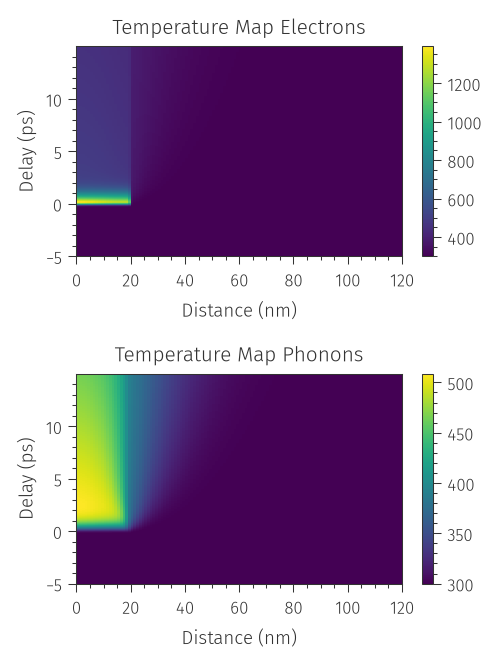

In [35]:
plt.figure(figsize=[3.4, 4.5])
plt.subplot(2, 1, 1)
plt.pcolormesh(
    res_temp.quantity("distances", "nm"),
    res_temp.quantity("delays", "ps"),
    res_temp.temp_map[:, :, 0],
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map Electrons")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_temp.quantity("distances", "nm"),
    res_temp.quantity("delays", "ps"),
    res_temp.temp_map[:, :, 1],
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map Phonons")

plt.tight_layout()
plt.show()

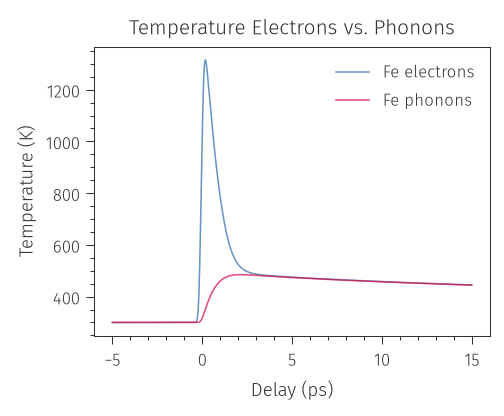

In [36]:
plt.figure()
select = S.positions_per_unique_layer["Fe"]
plt.plot(
    res_temp.quantity("delays", "ps"),
    np.mean(res_temp.temp_map[:, select, 0], 1),
    label="Fe electrons",
)
plt.plot(
    res_temp.quantity("delays", "ps"),
    np.mean(res_temp.temp_map[:, select, 1], 1),
    label="Fe phonons",
)
plt.ylabel("Temperature (K)")
plt.xlabel("Delay (ps)")
plt.legend()
plt.title("Temperature Electrons vs. Phonons")
plt.show()

## Energy map

It is also possible to translate the temperature maps into energy maps and energy flux maps.
The later is especially interesting for multi-subsystem simulations.

:::{versionadded} 2.4.0
Calculation of energy maps and energy flux maps from heat diffusion in {py:class}`Heat <udkm1Dsim.simulations.heat.Heat>`
:::

Elapsed time for _energy_map_: 0.007318 s


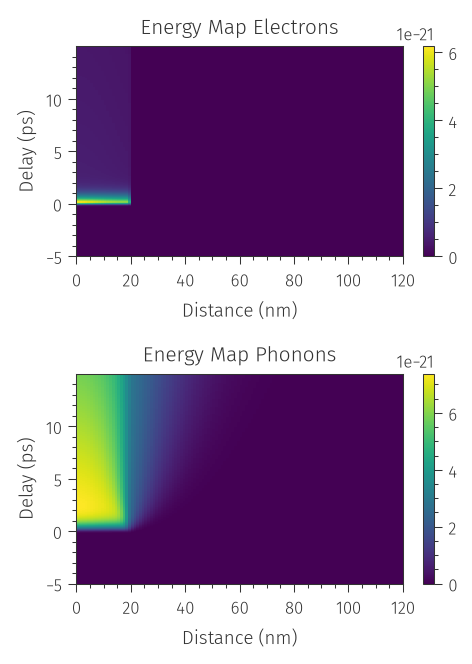

In [37]:
res_energy = h.get_energy_map(res_temp)

plt.figure(figsize=[3.4, 4.5])
plt.subplot(2, 1, 1)
plt.pcolormesh(
    res_energy.quantity("distances", "nm"),
    res_energy.quantity("delays", "ps"),
    res_energy.energy_map[:, :, 0],
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Energy Map Electrons")

plt.subplot(2, 1, 2)
plt.pcolormesh(
    res_energy.quantity("distances", "nm"),
    res_energy.quantity("delays", "ps"),
    res_energy.energy_map[:, :, 1],
    shading="auto",
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Energy Map Phonons")

plt.tight_layout()
plt.show()

## Energy Flux Map

Elapsed time for _energy_flux_map_: 0.006791 s


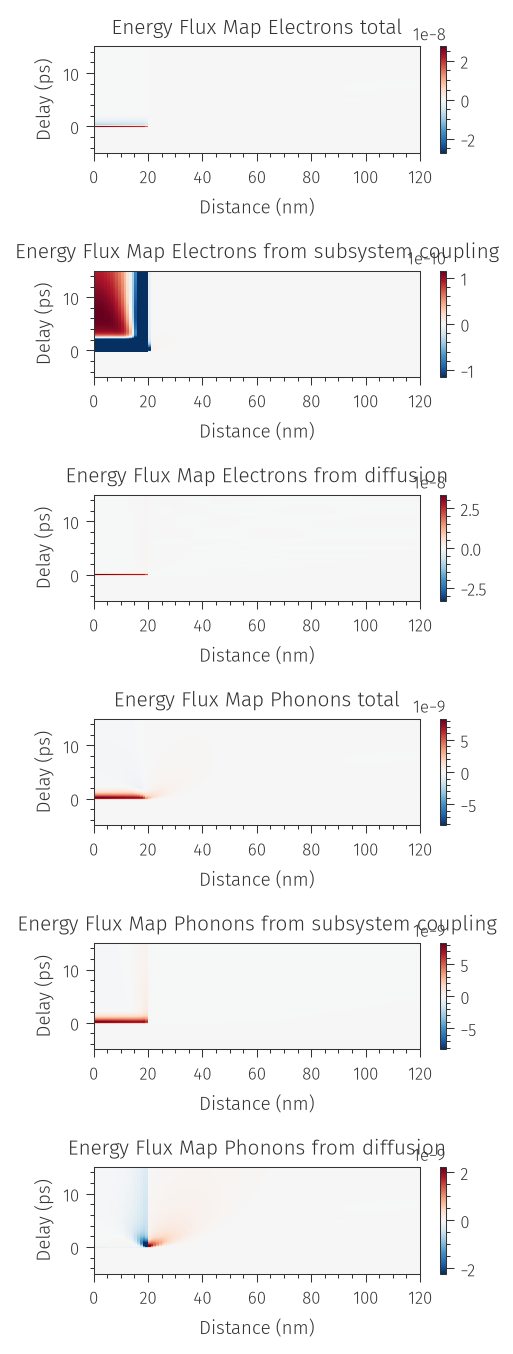

In [38]:
res_flux = h.get_energy_flux_map(res_temp)

plt.figure(figsize=[3.4, 9.1])
plt.subplot(6, 1, 1)
flux = res_flux.total_energy_flux_map[:, :, 0]
plt.pcolormesh(
    res_flux.quantity("distances", "nm"),
    res_flux.quantity("delays", "ps"),
    flux,
    shading="auto",
    cmap="RdBu_r",
    vmin=-np.max(flux),
    vmax=np.max(flux),
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Energy Flux Map Electrons total")

plt.subplot(6, 1, 2)
flux = res_flux.coupling_energy_flux_map[:, :, 0]
plt.pcolormesh(
    res_flux.quantity("distances", "nm"),
    res_flux.quantity("delays", "ps"),
    flux,
    shading="auto",
    cmap="RdBu_r",
    vmin=-np.max(flux),
    vmax=np.max(flux),
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Energy Flux Map Electrons from subsystem coupling")

plt.subplot(6, 1, 3)
flux = res_flux.diffusion_energy_flux_map[:, :, 0]
plt.pcolormesh(
    res_flux.quantity("distances", "nm"),
    res_flux.quantity("delays", "ps"),
    flux,
    shading="auto",
    cmap="RdBu_r",
    vmin=-np.max(flux),
    vmax=np.max(flux),
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Energy Flux Map Electrons from diffusion")

plt.subplot(6, 1, 4)
flux = res_flux.total_energy_flux_map[:, :, 1]
plt.pcolormesh(
    res_flux.quantity("distances", "nm"),
    res_flux.quantity("delays", "ps"),
    flux,
    shading="auto",
    cmap="RdBu_r",
    vmin=-np.max(flux),
    vmax=np.max(flux),
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Energy Flux Map Phonons total")

plt.subplot(6, 1, 5)
flux = res_flux.coupling_energy_flux_map[:, :, 1]
plt.pcolormesh(
    res_flux.quantity("distances", "nm"),
    res_flux.quantity("delays", "ps"),
    flux,
    shading="auto",
    cmap="RdBu_r",
    vmin=-np.max(flux),
    vmax=np.max(flux),
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Energy Flux Map Phonons from subsystem coupling")

plt.subplot(6, 1, 6)
flux = res_flux.diffusion_energy_flux_map[:, :, 1]
plt.pcolormesh(
    res_flux.quantity("distances", "nm"),
    res_flux.quantity("delays", "ps"),
    flux,
    shading="auto",
    cmap="RdBu_r",
    vmin=-np.max(flux),
    vmax=np.max(flux),
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Energy Flux Map Phonons from diffusion")

plt.tight_layout()
plt.show()

## Gallery Plot

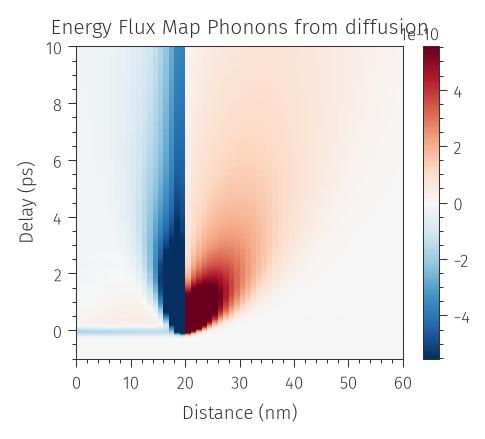

In [39]:
plt.figure(figsize=[3.4, 3])
flux = res_flux.diffusion_energy_flux_map[:, :, 1]
plt.pcolormesh(
    res_flux.quantity("distances", "nm"),
    res_flux.quantity("delays", "ps"),
    flux,
    shading="auto",
    cmap="RdBu_r",
    vmin=-0.25 * np.max(flux),
    vmax=0.25 * np.max(flux),
)
plt.colorbar()

plt.xlim(0, 60)
plt.ylim(-1, 10)

plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Energy Flux Map Phonons from diffusion")

plt.tight_layout()
plt.show()